<a href="https://colab.research.google.com/github/vitoriaayres/NOTEBOOKS_COMPILADOS/blob/main/onera_satellite.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt

import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers

In [2]:
import kagglehub
path= kagglehub.dataset_download(  "soumikrakshit/onera-satellite-change-detection-dataset")

print("Path to dataset files:", path)

100%|██████████| 504M/504M [00:06<00:00, 78.8MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/soumikrakshit/onera-satellite-change-detection-dataset/versions/1


In [ ]:
for root, dirs, files in os.walk(path):
  level= root.replace(path, '').count(os.sep)
  indent= ' ' * level

  print(f'{indent}{os.path.basename(root)}/')

  for file in files[:5]:
    print(f'{indent} {file}')

In [4]:
images_path = os.path.join(path, 'images', 'Onera Satellite Change Detection dataset - Images')
labels_path = os.path.join(path, 'train_labels', 'Onera Satellite Change Detection dataset - Train Labels')

print('IMAGES: ', images_path)
print('LABELS', labels_path)

IMAGES:  /root/.cache/kagglehub/datasets/soumikrakshit/onera-satellite-change-detection-dataset/versions/1/images/Onera Satellite Change Detection dataset - Images
LABELS /root/.cache/kagglehub/datasets/soumikrakshit/onera-satellite-change-detection-dataset/versions/1/train_labels/Onera Satellite Change Detection dataset - Train Labels


In [5]:
image_files= os.listdir(images_path)
label_files= os.listdir(labels_path)

print('NUMERO DE ARQUIVOS EM IMAGENS: ',  len(image_files))
print('NUMERO DE ARQUIVOS EM TRAIN_LABELS', len(label_files))

NUMERO DE ARQUIVOS EM IMAGENS:  28
NUMERO DE ARQUIVOS EM TRAIN_LABELS 15


In [6]:
print('PRIMEIRAS IMAGENS')
for file in image_files[:20]:
  print(file)

print('\nPRIMEIROS LABELS: ')
for file in label_files[:20]:
  print(file)

PRIMEIRAS IMAGENS
beihai
README.txt
mumbai
valencia
bercy
beirut
rennes
milano
chongqing
abudhabi
bordeaux
brasilia
cupertino
saclay_w
montpellier
aguasclaras
norcia
train.txt
all.txt
lasvegas

PRIMEIROS LABELS: 
beihai
README.txt
mumbai
bercy
beirut
rennes
abudhabi
bordeaux
cupertino
aguasclaras
paris
pisa
hongkong
saclay_e
nantes


In [7]:
from collections import Counter
image_extensions= Counter(
    os.path.splitext(f)[1].lower()
    for f in image_files
)
label_extensions= Counter(
    os.path.splitext(f)[1].lower()
    for f in label_files
)

print('EXTENSÕES DAS IMAGENS:  ')
print(image_extensions)
print('\nEXTENSÕES DOS LABELS: ')
print(label_extensions)

EXTENSÕES DAS IMAGENS:  
Counter({'': 24, '.txt': 4})

EXTENSÕES DOS LABELS: 
Counter({'': 14, '.txt': 1})


In [8]:
from PIL import Image
import os

first_city_name = image_files[0]
city_imgs_path = os.path.join(images_path, first_city_name, 'imgs_1')

print(f"Attempting to access: {city_imgs_path}")

if not os.path.exists(city_imgs_path):
    print(f"Error: Directory does not exist: {city_imgs_path}")
    city_dir_for_list = os.path.join(images_path, first_city_name)
    print(f"Contents of {city_dir_for_list}:")
    try:
        city_dir_contents = os.listdir(city_dir_for_list)
        for item in city_dir_contents:
            print(f" - {item}")
    except FileNotFoundError:
        print(f"Error: City directory itself not found: {city_dir_for_list}")
    except NotADirectoryError:
        print(f"Error: {city_dir_for_list} is not a directory.")
    print("Cannot proceed: The expected 'imgs_1' directory or its parent was not found.")
else:
    image_files_in_city_dir = os.listdir(city_imgs_path)

    actual_image_filename = next((f for f in image_files_in_city_dir if f.lower().endswith(('.png', '.tif', '.jpg', '.jpeg'))), None)

    if actual_image_filename:
        first_image_full_path = os.path.join(city_imgs_path, actual_image_filename)
        img = Image.open(first_image_full_path)

        print('ARQUIVO', actual_image_filename)
        print('TAMANHO', img.size)
        print('MODO:  ', img.mode)
    else:
        print(f"No image files found in {city_imgs_path}")

Attempting to access: /root/.cache/kagglehub/datasets/soumikrakshit/onera-satellite-change-detection-dataset/versions/1/images/Onera Satellite Change Detection dataset - Images/beihai/imgs_1
ARQUIVO T49QCD_20161209T031122_B07.tif
TAMANHO (386, 451)
MODO:   I;16


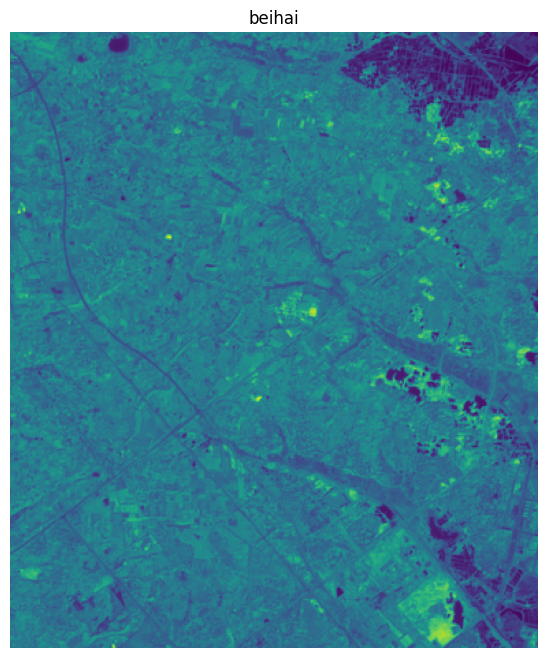

In [9]:
plt.figure(figsize=(8,8))
plt.imshow(img)
plt.axis('off')
plt.title(image_files[0])
plt.show()

In [10]:
first_city_name_label = label_files[0]
city_label_dir_path = os.path.join(labels_path, first_city_name_label)

print(f"Attempting to access: {city_label_dir_path}")

if not os.path.exists(city_label_dir_path):
    print(f"Error: Directory does not exist: {city_label_dir_path}")
    print(f"Contents of {labels_path}:")
    try:
        labels_root_contents = os.listdir(labels_path)
        for item in labels_root_contents:
            print(f" - {item}")
    except FileNotFoundError:
        print(f"Error: Labels root directory itself not found: {labels_path}")
    except NotADirectoryError:
        print(f"Error: {labels_path} is not a directory.")
    print("Cannot proceed: The expected city directory for labels was not found.")
elif os.path.isdir(city_label_dir_path):
    print(f"'{city_label_dir_path}' is a directory. Listing its contents:")
    try:
        city_label_contents = os.listdir(city_label_dir_path)
        for item in city_label_contents:
            print(f" - {item}")

        city_cm_label_path = os.path.join(city_label_dir_path, 'cm')
        print(f"Attempting to access 'cm' subdirectory: {city_cm_label_path}")

        if os.path.exists(city_cm_label_path) and os.path.isdir(city_cm_label_path):
            label_files_in_cm = os.listdir(city_cm_label_path)
            actual_label_filename = next((f for f in label_files_in_cm if f.lower().endswith(('.png', '.tif', '.jpg', '.jpeg'))), None)

            if actual_label_filename:
                first_label_full_path = os.path.join(city_cm_label_path, actual_label_filename)
                label = Image.open(first_label_full_path)
                print('ARQUIVO:  ', actual_label_filename)
                print('TAMANHO:  ', label.size)
                print('MODE:     ', label.mode)
            else:
                print(f"No image files found in {city_cm_label_path}.")
        else:
            print(f"'cm' subdirectory not found or is not a directory in {city_label_dir_path}.")

    except FileNotFoundError:
        print(f"Error: City label directory itself not found: {city_label_dir_path}")
    except NotADirectoryError:
        print(f"Error: {city_label_dir_path} is not a directory.")
else:
    first_label = os.path.join(labels_path, first_city_name_label)
    label = Image.open(first_label)
    print('ARQUIVO:  ', first_city_name_label)
    print('TAMANHO:  ', label.size)
    print('MODE:     ', label.mode)

Attempting to access: /root/.cache/kagglehub/datasets/soumikrakshit/onera-satellite-change-detection-dataset/versions/1/train_labels/Onera Satellite Change Detection dataset - Train Labels/beihai
'/root/.cache/kagglehub/datasets/soumikrakshit/onera-satellite-change-detection-dataset/versions/1/train_labels/Onera Satellite Change Detection dataset - Train Labels/beihai' is a directory. Listing its contents:
 - cm
Attempting to access 'cm' subdirectory: /root/.cache/kagglehub/datasets/soumikrakshit/onera-satellite-change-detection-dataset/versions/1/train_labels/Onera Satellite Change Detection dataset - Train Labels/beihai/cm
ARQUIVO:   cm.png
TAMANHO:   (772, 902)
MODE:      RGBA


In [12]:
label_array= np.array(label)

print('SHAPE:  ', label_array.shape)
print('VALORES ÚNICOS: ')

values, counts= np.unique(
    label_array,
    return_counts= True
)
for value, count in zip(values, counts):
  print(f'VALOR {value}: {count} pixels')

SHAPE:   (902, 772, 4)
VALORES ÚNICOS: 
VALOR 0: 2037078 pixels
VALOR 255: 748298 pixels


In [13]:
IMG_SIZE= 128
BATCH_SIZE= 8
EPOCHS= 30

SEED= 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

In [14]:
#---------------------------------------------------------------------------------------------------------------------------------------------------------
import glob
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

In [15]:
IMG_SIZE= 128
BATCH_SIZE= 8
EPOCHS= 10
SEED= 42

np.random.seed(SEED)
tf.random.set_seed(SEED)

print('IMG_SIZE: ', IMG_SIZE)
print('BATCH_SIZE: ', BATCH_SIZE)
print('EPOCHS: ', EPOCHS)

IMG_SIZE:  128
BATCH_SIZE:  8
EPOCHS:  10


In [16]:
train_labels_root = os.path.join(path, "train_labels")
train_regions = sorted([
    d for d in os.listdir(labels_path)
    if os.path.isdir(os.path.join(labels_path, d))
])

print("Regiões encontradas:")
print(train_regions)
print("\nTotal:", len(train_regions))


Regiões encontradas:
['abudhabi', 'aguasclaras', 'beihai', 'beirut', 'bercy', 'bordeaux', 'cupertino', 'hongkong', 'mumbai', 'nantes', 'paris', 'pisa', 'rennes', 'saclay_e']

Total: 14


In [17]:
images_root= os.path.join(path, 'images')
labels_root= os.path.join(path, 'train_labels')

print('IMAGES ROOT: ')
print(images_root)
print('\nLABELS ROOT: ')
print(labels_root)

IMAGES ROOT: 
/root/.cache/kagglehub/datasets/soumikrakshit/onera-satellite-change-detection-dataset/versions/1/images

LABELS ROOT: 
/root/.cache/kagglehub/datasets/soumikrakshit/onera-satellite-change-detection-dataset/versions/1/train_labels


In [18]:
region= train_regions[0]

region_path= os.path.join(images_root, region)

print('REGIÃO: ', region)

for root, dirs, files in os.walk(region_path):
  level= root.replace(region_path, ' ').count(os.sep)
  indent= ' ' * level

  print(f'{indent}{os.path.basename(root)}')

  for file in files[:5]:
    print(f'{indent} {file}')

REGIÃO:  abudhabi


In [19]:
def get_rgb_paths(region_path):
  print(f"  [get_rgb_paths] Received region_path: {region_path}")
  img1_path= os.path.join(region_path, 'imgs_1_rect')
  img2_path= os.path.join(region_path, 'imgs_2_rect')

  # Corrected typo: 'BO3.tif' to 'B03.tif'
  bands= ['B02.tif', 'B03.tif', 'B04.tif']

  paths1= [
      os.path.join(img1_path, band)
      for band in bands
  ]
  paths2= [
      os.path.join(img2_path, band)
      for band in bands
  ]
  print(f"  [get_rgb_paths] Paths1: {paths1[0]} (and others)")
  return paths1, paths2

In [20]:
def load_rgb(paths):
  channels= []

  for file_path in paths:
    img= Image.open(file_path)
    img= np.array(img).astype(np.float32)

    channels.append(img)
  image= np.stack(channels, axis=-1)

  return image

In [21]:
def normalize_image(image):
  image= image.astype(np.float32)
  min_val= image.min()
  max_val= image.max()

  if max_val > min_val:
    image= (image - min_val) / (max_val - min_val)
  else:
    image= np.zeros_likes(image)
  return image

In [22]:
def load_region(city_name):
  print(f"[load_region] Loading region: {city_name}")

  image_city_path = os.path.join(images_path, city_name)
  print(f"[load_region] image_city_path: {image_city_path}")
  paths1, paths2= get_rgb_paths(image_city_path)

  image1= load_rgb(paths1)
  image2= load_rgb(paths2)

  image1= normalize_image(image1)
  image2= normalize_image(image2)

  label_full_path= os.path.join(
      labels_path,
      city_name,
      'cm',
      'cm.png'
  )
  print(f"[load_region] label_full_path: {label_full_path}")
  mask= np.array(
      Image.open(label_full_path).convert('L')
  ).astype(np.float32)

  if mask.ndim == 3:
      if mask.shape[-1] == 1:
          mask = np.squeeze(mask, axis=-1)
      elif mask.shape[-1] > 1:
          mask = mask[:, :, 0]

  mask= (mask > 0).astype(np.float32)
  return image1, image2, mask

In [23]:
image1, image2, mask = load_region(
    train_regions[0]
)

print("Imagem T1:", image1.shape)
print("Imagem T2:", image2.shape)
print("Mask:", mask.shape)

print("\nValores da máscara:")
print(np.unique(mask))

[load_region] Loading region: abudhabi
[load_region] image_city_path: /root/.cache/kagglehub/datasets/soumikrakshit/onera-satellite-change-detection-dataset/versions/1/images/Onera Satellite Change Detection dataset - Images/abudhabi
  [get_rgb_paths] Received region_path: /root/.cache/kagglehub/datasets/soumikrakshit/onera-satellite-change-detection-dataset/versions/1/images/Onera Satellite Change Detection dataset - Images/abudhabi
  [get_rgb_paths] Paths1: /root/.cache/kagglehub/datasets/soumikrakshit/onera-satellite-change-detection-dataset/versions/1/images/Onera Satellite Change Detection dataset - Images/abudhabi/imgs_1_rect/B02.tif (and others)
[load_region] label_full_path: /root/.cache/kagglehub/datasets/soumikrakshit/onera-satellite-change-detection-dataset/versions/1/train_labels/Onera Satellite Change Detection dataset - Train Labels/abudhabi/cm/cm.png
Imagem T1: (799, 785, 3)
Imagem T2: (799, 785, 3)
Mask: (799, 785)

Valores da máscara:
[0. 1.]


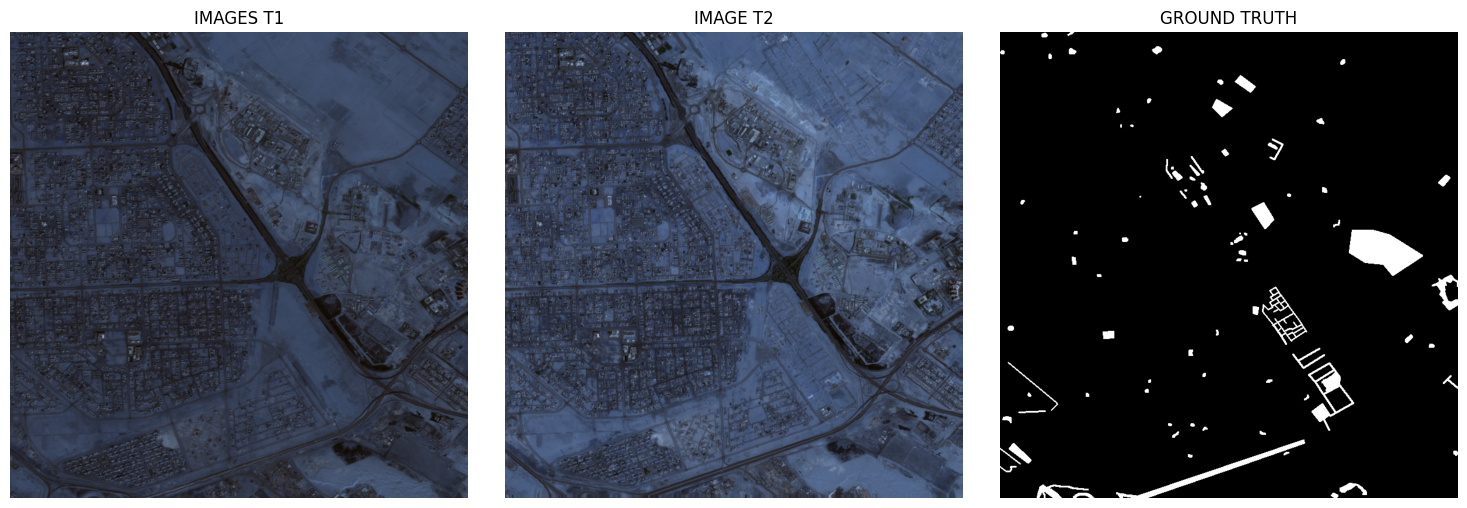

In [24]:
plt.figure(figsize=(15,5))

plt.subplot(1,3,1)
plt.imshow(image1)
plt.title('IMAGES T1')
plt.axis('OFF')

plt.subplot(1,3,2)
plt.imshow(image2)
plt.title('IMAGE T2')
plt.axis('OFF')

plt.subplot(1,3,3)
plt.imshow(mask, cmap="gray")
plt.title('GROUND TRUTH')
plt.axis('OFF')

plt.tight_layout()
plt.show()


In [26]:
def create_patches(
    image1,
    image2,
    mask,
    patch_size= 128
):
  patches1= []
  patches2= []
  masks= []

  height, width= mask.shape

  for y in range(0, height - patch_size + 1, patch_size):
    for x in range(0, width - patch_size + 1, patch_size):

      patch1= image1[
          y:y+patch_size,
          x:x+patch_size
      ]

      patch2= image2[
          y:y+patch_size,
          x:x+patch_size
      ]

      patch_mask = mask[
          y:y+patch_size,
          x:x+patch_size
      ]

      patches1.append(patch1)
      patches2.append(patch2)
      masks.append(patch_mask) # Corrected variable name: mask -> masks, and added patch_mask
  return(
      np.array(patches1),
      np.array(patches2),
      np.array(masks)
  )

In [ ]:
X1 = []
X2 = []
Y = []

for region in train_regions:

    print("Processando:", region)

    img1, img2, mask = load_region(region)

    p1, p2, pmask = create_patches(
        img1,
        img2,
        mask,
        IMG_SIZE
    )

    X1.append(p1)
    X2.append(p2)
    Y.append(pmask)

In [28]:
X1_stacked = np.concatenate(X1, axis=0)
X2_stacked = np.concatenate(X2, axis=0)
Y_stacked = np.concatenate(Y, axis=0)

print(f"Shape de X1_stacked: {X1_stacked.shape}")
print(f"Shape de X2_stacked: {X2_stacked.shape}")
print(f"Shape de Y_stacked: {Y_stacked.shape}")

Shape de X1_stacked: (349, 128, 128, 3)
Shape de X2_stacked: (349, 128, 128, 3)
Shape de Y_stacked: (349, 128, 128)


In [29]:
Y_stacked = np.expand_dims(
    Y_stacked,
    axis=-1
)

print(Y_stacked.shape)

(349, 128, 128, 1)


In [30]:
print('TOTAL DE PATCHES: ', len(X1))

TOTAL DE PATCHES:  14


In [31]:
changed_pixels= np.sum(Y == 1)
unchanged_pixels= np.sum(Y == 0)

total_pixels= changed_pixels + unchanged_pixels

print('PIXELS SEM MUDANÇA', unchanged_pixels)
print('PIXELS COM MUDANÇA', changed_pixels)

print(
    '\nPERCENTUAL DE MUDANÇA',
    100 * changed_pixels / total_pixels,
    '%'
)

PIXELS SEM MUDANÇA 0
PIXELS COM MUDANÇA 0

PERCENTUAL DE MUDANÇA nan %


/tmp/ipykernel_3248/1686141495.py:11: RuntimeWarning: invalid value encountered in scalar divide
  100 * changed_pixels / total_pixels,


In [32]:
from sklearn.model_selection import train_test_split

X1_train, X1_val, X2_train, X2_val, Y_train, Y_val= train_test_split(
    X1_stacked,
    X2_stacked,
    Y_stacked,
    test_size= 0.2,
    random_state= SEED
)
print('TREINO: ', X1_train.shape)
print('VALIDAÇÃO: ', X1_val.shape)

TREINO:  (279, 128, 128, 3)
VALIDAÇÃO:  (70, 128, 128, 3)


In [33]:
def augment_pair(image1, image2, mask):
  if tf.random.uniform(()) > 0.5:
    image1= tf.image.flip_left_right(image1)
    image2= tf.image.flip_left_right(image2)
    mask= tf.image.flip_left_right(mask)

  if tf.random.uniform(()) > 0.5:
    image1= tf.image.flip_up_down(image1)
    image2= tf.image.flip_up_down(image2)
    mask= tf.image.flip_up_down(mask)

  return image1, image2, mask

In [34]:
train_dataset = tf.data.Dataset.from_tensor_slices(
    (
    (X1_train, X2_train),
    Y_train
    )
)
val_dataset= tf.data.Dataset.from_tensor_slices(
    (
        (X1_val, X2_val),
        Y_val
    )
)

In [35]:
def augment_dataset(inputs, mask):
  image1, image2= inputs

  image1, image2, mask= augment_pair(
      image1,
      image2,
      mask
  )
  return (image1, image2), mask
train_dataset= train_dataset.map(
    augment_dataset,
    num_parallel_calls=tf.data.AUTOTUNE
)

In [36]:
train_dataset = train_dataset.batch(
    BATCH_SIZE
).prefetch(
    tf.data.AUTOTUNE
)

val_dataset = val_dataset.batch(
    BATCH_SIZE
).prefetch(
    tf.data.AUTOTUNE
)

In [37]:
def conv_block(x, filters):
  x= layers.Conv2D(
      filters,
      3,
      padding="same",
      activation= 'relu'
  )(x)

  x= layers.BatchNormalization()(x)
  x= layers.Conv2D(
      filters,
      3,
      padding= 'same',
      activation= 'relu'
  )(x)

  x= layers.BatchNormalization()(x)

  return x

In [38]:
input_t1= layers.Input(
    shape= (IMG_SIZE, IMG_SIZE, 3),
    name= 'image_t1'
)
input_t2= layers.Input(
    shape= (IMG_SIZE, IMG_SIZE, 3),
    name= 'image_t2'
)

In [39]:
def encoder(inputs):
  c1= conv_block(inputs, 32)
  p1= layers.MaxPooling2D()(c1)

  c2= conv_block(p1, 64)
  p2= layers.MaxPooling2D()(c2)

  c3= conv_block(p2, 128)
  p3= layers.MaxPooling2D()(c3)

  c4= conv_block(p3, 256)

  return c1, c2, c3, c4

In [40]:
t1_c1, t1_c2, t1_c3, t1_c4 = encoder(
    input_t1
)

t2_c1, t2_c2, t2_c3, t2_c4 = encoder(
    input_t2
)

In [41]:
d1= layers.Lambda(
    lambda x: tf.abs(x[0] - x[1])
)([t1_c1, t2_c1])

d2= layers.Lambda(
    lambda x: tf.abs(x[0] - x[1])
)([t1_c2, t2_c2])

d3= layers.Lambda(
    lambda x: tf.abs(x[0] - x[1])
)([t1_c3, t2_c3])

d4= layers.Lambda(
    lambda x: tf.abs(x[0] - x[1])
)([t1_c4, t2_c4])

In [42]:
x = layers.UpSampling2D()(d4)

x = layers.Concatenate()([
    x,
    d3
])

x = conv_block(x, 128)


x = layers.UpSampling2D()(x)

x = layers.Concatenate()([
    x,
    d2
])

x = conv_block(x, 64)


x = layers.UpSampling2D()(x)

x = layers.Concatenate()([
    x,
    d1
])

x = conv_block(x, 32)

In [43]:
output= layers.Conv2D(
    1,
    1,
    activation='sigmoid',
    name= 'change_mask'
)(x)

In [44]:
model= keras.Model(
    inputs=[input_t1, input_t2],
    outputs= output
)
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ image_t1            │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ image_t2            │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 128, 128,  │        896 │ image_t1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_8 (Conv2D)   │ (None, 128, 128,  │        896 │ image_t2[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 128, 128,  │        128 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │        128 │ conv2d_8[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 128, 128,  │      9,248 │ batch_normalizat… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_9 (Conv2D)   │ (None, 128, 128,  │      9,248 │ batch_normalizat… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │        128 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │        128 │ conv2d_9[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 64, 64,    │          0 │ batch_normalizat… │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_3     │ (None, 64, 64,    │          0 │ batch_normalizat… │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 64, 64,    │     18,496 │ max_pooling2d[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_10 (Conv2D)  │ (None, 64, 64,    │     18,496 │ max_pooling2d_3[… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        256 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        256 │ conv2d_10[0][0]   │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 64, 64,    │     36,928 │ batch_normalizat

 Total params: 3,128,609 (11.93 MB)

 Trainable params: 3,123,873 (11.92 MB)

 Non-trainable params: 4,736 (18.50 KB)

In [45]:
def dice_coefficient(y_true, y_pred):
  smooth= 1e-6
  y_true= tf.cast(
      y_true,
      tf.float32
  )
  intersection= tf.reduce_sum(
      y_true * y_pred
  )
  return(
      2.0 * intersection + smooth
  ) / (
      tf.reduce_sum(y_true) +
      tf.reduce_sum(y_pred) +
      smooth
  )

In [46]:
def dice_loss(y_true, y_pred):
  return 1- dice_coefficient(
      y_true,
      y_pred
  )

In [47]:
bce= keras.losses.BinaryCrossentropy()

def combined_loss(y_true, y_pred):
  binary_loss= bce(
      y_true,
      y_pred
  )
  d_loss= dice_loss(
      y_true,
      y_pred
  )

  return binary_loss + d_loss

In [48]:
def iou_metric(y_true, y_pred):
  y_pred= tf.cast(
      y_pred > 0.5,
      tf.float32
  )
  intersection= tf.reduce_sum(
      y_true * y_pred
  )
  union= (
      tf.reduce_sum(y_true) +
      tf.reduce_sum(y_pred) -
      intersection
  )
  return (
      intersection + 1e-6
  ) / (
      union + 1e-6
  )

In [49]:
model.compile(
    optimizer= keras.optimizers.Adam(
        learning_rate= 1e-4
    ),
    loss= combined_loss,
    metrics= [
        dice_coefficient,
        iou_metric
    ]
)

In [50]:
callbacks = [

    keras.callbacks.ModelCheckpoint(
        "best_change_detection.keras",
        monitor="val_iou_metric",
        mode="max",
        save_best_only=True
    ),

    keras.callbacks.EarlyStopping(
        monitor="val_iou_metric",
        patience=7,
        mode="max",
        restore_best_weights=True
    ),

    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        verbose=1
    )
]

In [51]:
history= model.fit(
    train_dataset,
    validation_data= val_dataset,
    epochs= EPOCHS,
    callbacks= callbacks
)

Epoch 1/10
35/35 ━━━━━━━━━━━━━━━━━━━━ 60s 804ms/step - dice_coefficient: 0.0469 - iou_metric: 0.0254 - loss: 1.7480 - val_dice_coefficient: 0.0433 - val_iou_metric: 0.0189 - val_loss: 1.6559 - learning_rate: 1.0000e-04
Epoch 2/10
35/35 ━━━━━━━━━━━━━━━━━━━━ 2s 64ms/step - dice_coefficient: 0.0522 - iou_metric: 0.0347 - loss: 1.6560 - val_dice_coefficient: 0.0431 - val_iou_metric: 0.0144 - val_loss: 1.6152 - learning_rate: 1.0000e-04
Epoch 3/10
35/35 ━━━━━━━━━━━━━━━━━━━━ 2s 60ms/step - dice_coefficient: 0.0564 - iou_metric: 0.0469 - loss: 1.6167 - val_dice_coefficient: 0.0431 - val_iou_metric: 7.9137e-04 - val_loss: 1.5835 - learning_rate: 1.0000e-04
Epoch 4/10
35/35 ━━━━━━━━━━━━━━━━━━━━ 2s 60ms/step - dice_coefficient: 0.0613 - iou_metric: 0.0605 - loss: 1.5903 - val_dice_coefficient: 0.0428 - val_iou_metric: 1.4982e-04 - val_loss: 1.5069 - learning_rate: 1.0000e-04
Epoch 5/10
35/35 ━━━━━━━━━━━━━━━━━━━━ 2s 60ms/step - dice_coefficient: 0.0666 - iou_metric: 0.0744 - loss: 1.5666 - val_di

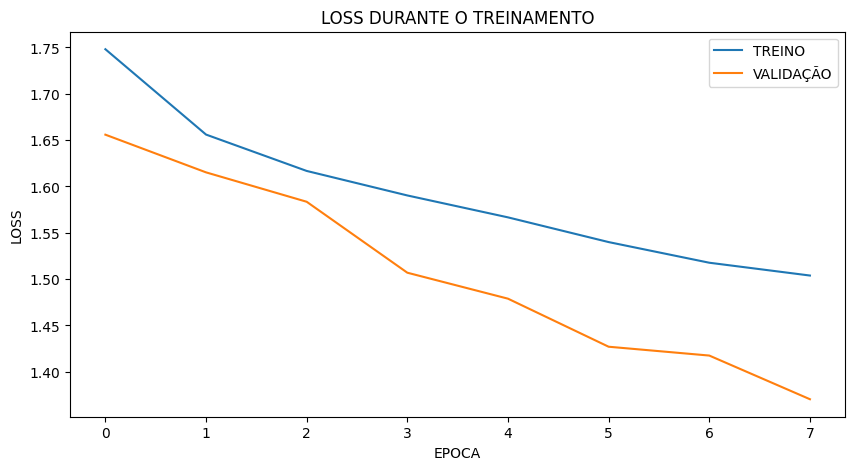

In [52]:
plt.figure(figsize=(10,5))

plt.plot(
    history.history['loss'],
    label= 'TREINO'
)

plt.plot(
    history.history['val_loss'],
    label= 'VALIDAÇÃO'
)

plt.xlabel('EPOCA')
plt.ylabel('LOSS')

plt.title('LOSS DURANTE O TREINAMENTO')
plt.legend()
plt.show()

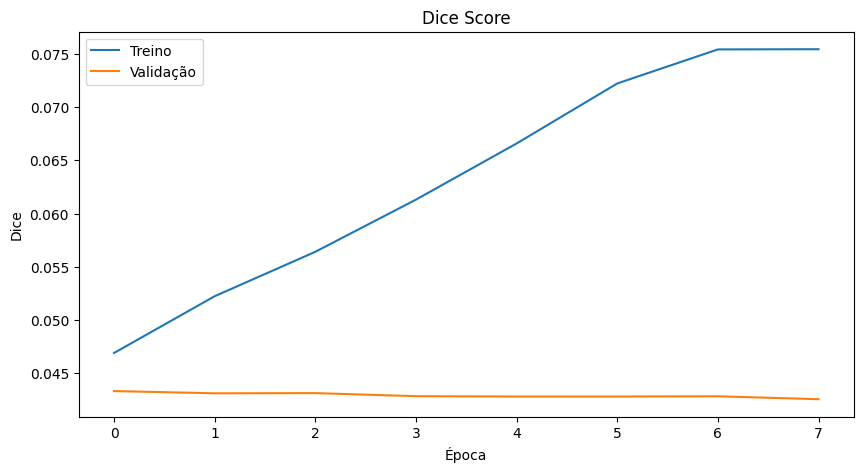

In [54]:
plt.figure(figsize=(10, 5))

plt.plot(
    history.history["dice_coefficient"],
    label="Treino"
)

plt.plot(
    history.history["val_dice_coefficient"],
    label="Validação"
)

plt.xlabel("Época")
plt.ylabel("Dice")

plt.title("Dice Score")

plt.legend()
plt.show()

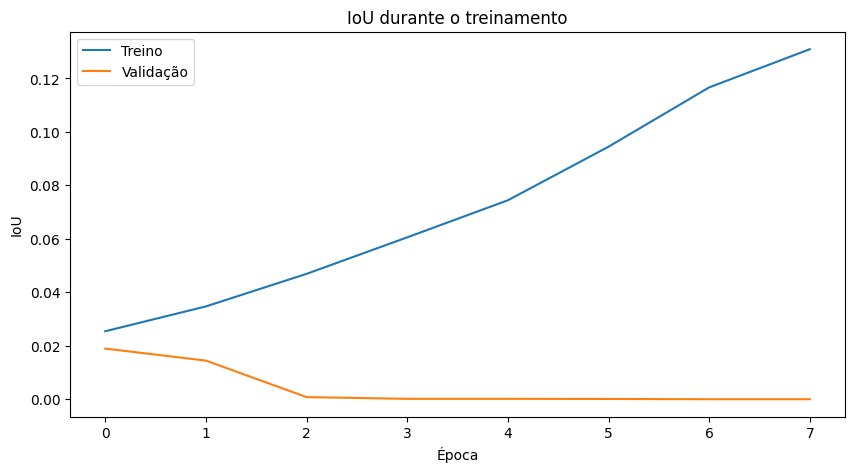

In [55]:
plt.figure(figsize=(10, 5))

plt.plot(
    history.history["iou_metric"],
    label="Treino"
)

plt.plot(
    history.history["val_iou_metric"],
    label="Validação"
)

plt.xlabel("Época")
plt.ylabel("IoU")

plt.title("IoU durante o treinamento")

plt.legend()
plt.show()

In [57]:
sample_index= 0
sample_t1= X1_val[
    sample_index: sample_index + 1
]
sample_t2= X2_val[
    sample_index: sample_index + 1
]
sample_mask= Y_val[
    sample_index
]
prediction= model.predict(
    [sample_t1, sample_t2],
    verbose= 0
)[0]
prediction = prediction[:, :, 0]

In [58]:
pred_mask= (
    prediction > 0.5
).astype(np.float32)

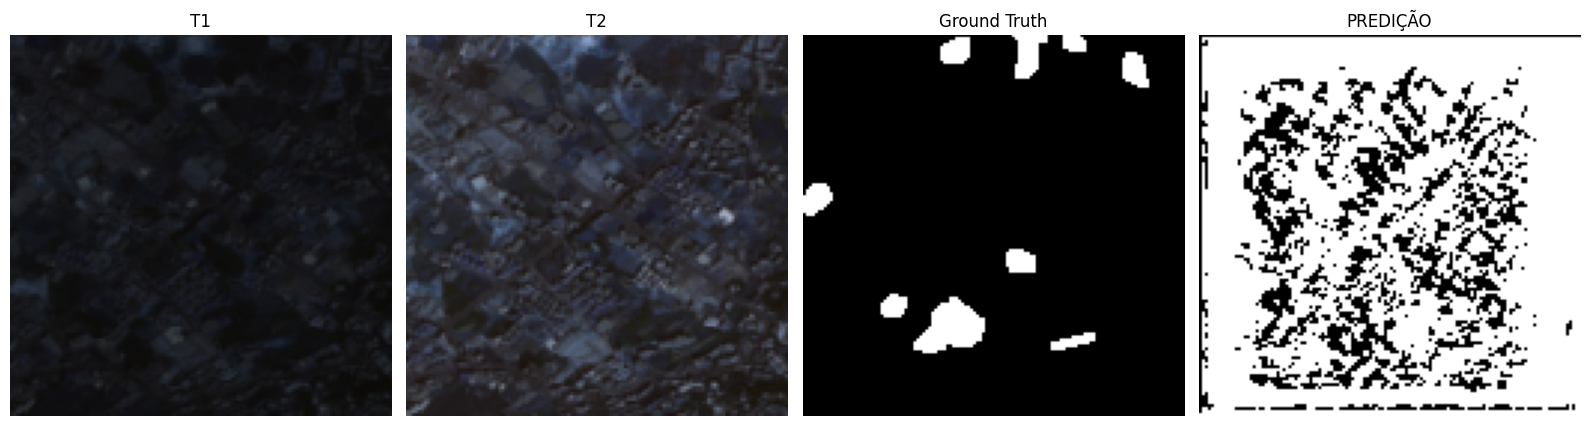

In [59]:
plt.figure(figsize=(16,5))

plt.subplot(1,4,1)
plt.imshow(sample_t1[0])
plt.title('T1')
plt.axis('OFF')

plt.subplot(1,4,2)
plt.imshow(sample_t2[0])
plt.title('T2')
plt.axis('OFF')

plt.subplot(1,4,3)
plt.imshow(sample_mask[:,:,0], cmap='gray')
plt.title('Ground Truth')
plt.axis('off')

plt.subplot(1,4,4)
plt.imshow(pred_mask, cmap='gray')
plt.title('PREDIÇÃO')
plt.axis('OFF')

plt.tight_layout()
plt.show()

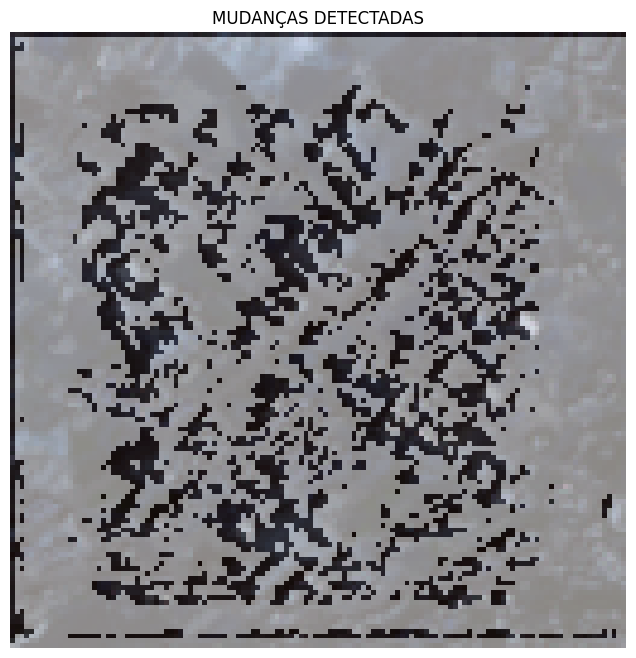

In [60]:
plt.figure(figsize=(8,8))

plt.imshow(sample_t2[0])

plt.imshow(
    pred_mask,
    alpha= 0.5,
    cmap= 'hot'
)
plt.title('MUDANÇAS DETECTADAS')
plt.axis('OFF')
plt.show()

In [62]:
results = model.evaluate(
    val_dataset,
    verbose=1
)

print("\nResultados:")

for name, value in zip(
    model.metrics_names,
    results
):
    print(
        f"{name}: {value:.4f}"
    )

9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - dice_coefficient: 0.0433 - iou_metric: 0.0189 - loss: 1.6559

Resultados:
loss: 1.6559
compile_metrics: 0.0433


In [63]:
model.save(
    'onera_change_detection.keras'
)
print('MODELO SALVO COM SUCESSO!')

MODELO SALVO COM SUCESSO!


In [65]:
from google.colab import files

files.download(
    "onera_change_detection.keras"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>